# Risk-Return Scatter

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Places each fund or asset by its annualised volatility (x) and annualised return (y), with lines of equal Sharpe ratio fanning out from the risk-free rate. It answers "was the return worth the risk?" for many investments at once, instead of comparing returns alone.

## When to use

- Compare a fund with its peer group or a set of indices
- Screen many investments for risk-adjusted performance
- Show where a proposed portfolio sits relative to the alternatives

## Avoid when

- The periods differ between funds (statistics must cover the same dates)
- More than about 100 points without highlighting (it becomes a cloud; filter or highlight)

## Alternatives

- Efficient frontier (for what is achievable)
- Ranked bar chart of Sharpe ratios

## Design tips

- Highlight the fund of interest and the benchmark; gray out the peers
- Add iso-Sharpe reference lines from the risk-free rate to make the trade-off visible
- Label only the points that matter

## Example

Simulated three-year statistics for 30 peer funds, the fund under review and its benchmark; 2% risk-free rate. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.ticker import PercentFormatter

### Data

In [2]:
rng = np.random.default_rng(12)
vol = rng.uniform(0.08, 0.24, 30)
ret = 0.02 + 0.35 * vol + rng.normal(0, 0.025, 30)
stats = pd.DataFrame({"ann_vol": vol, "ann_return": ret}, index=[f"Peer {i:02d}" for i in range(1, 31)])
stats.loc["Our fund"] = [0.155, 0.112]
stats.loc["Benchmark"] = [0.15, 0.085]
highlight, benchmark, rf = "Our fund", "Benchmark", 0.02
stats.tail()

,ann_vol,ann_return
Peer 28,0.219449,0.125944
Peer 29,0.145296,0.098273
Peer 30,0.115102,0.116649
Our fund,0.155000,0.112000
Benchmark,0.150000,0.085000


### Plot

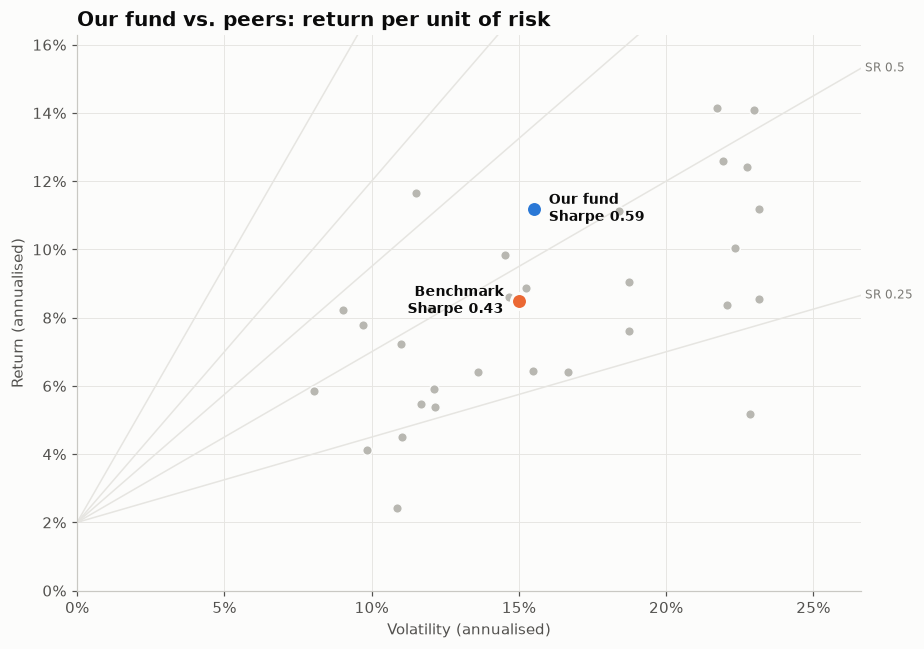

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 6))
others = stats.drop([highlight, benchmark])
xmax = stats["ann_vol"].max() * 1.15
for sharpe in [0.25, 0.5, 0.75, 1.0, 1.5]:
    ax.plot([0, xmax], [rf, rf + sharpe * xmax], color="#e6e5e1", linewidth=1, zorder=1)
    y_end = rf + sharpe * xmax
    if y_end < stats["ann_return"].max() * 1.15:
        ax.text(xmax, y_end, f" SR {sharpe}", fontsize=8, color="#7a7974", va="center")
ax.scatter(others["ann_vol"], others["ann_return"], s=40, color=GRAY, edgecolor="#fcfcfb", linewidth=1, zorder=2)
if len(others) <= 8:  # few peers: name them
    for name, (x, y) in others.iterrows():
        ax.annotate(name, (x, y), xytext=(7, 0), textcoords="offset points", va="center", fontsize=8.5,
                    color="#52514e")
for name, color in [(benchmark, PALETTE[1]), (highlight, PALETTE[0])]:
    x, y = stats.loc[name]
    ax.scatter(x, y, s=110, color=color, edgecolor="#fcfcfb", linewidth=2, zorder=3)
    left = name == benchmark
    ax.annotate(f"{name}\nSharpe {(y - rf) / x:.2f}", (x, y), xytext=(-10 if left else 10, 0),
                textcoords="offset points", ha="right" if left else "left", va="center", fontsize=9,
                weight="bold", color="#0b0b0b")
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, xmax)
ax.set_ylim(min(0, stats["ann_return"].min() * 1.1), stats["ann_return"].max() * 1.15)
ax.set_xlabel("Volatility (annualised)")
ax.set_ylabel("Return (annualised)")
ax.set_title(f"{highlight} vs. peers: return per unit of risk")
fig.tight_layout()
plt.show()

## How to read it

Up and to the left is better (more return for less risk). The thin gray rays are lines of equal Sharpe ratio: any fund above a ray beat that Sharpe ratio. The blue fund sits above the benchmark's ray, so its extra risk was rewarded.

## Try it with real data

**Source:** plotly.express.data.stocks() — 6 tech stocks and their equal-weight basket, weekly returns 2018–2019

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
prices = px.data.stocks().set_index("date")
weekly = prices.pct_change().dropna()
weekly["Equal-weight"] = weekly.mean(axis=1)
stats = pd.DataFrame({"ann_vol": weekly.std() * np.sqrt(52),
                      "ann_return": (1 + weekly).prod() ** (52 / len(weekly)) - 1})
highlight, benchmark, rf = "AAPL", "Equal-weight", 0.02
stats

,ann_vol,ann_return
GOOG,0.237193,0.101369
AAPL,0.269911,0.295376
AMZN,0.273777,0.226116
FB,0.310002,0.048081
NFLX,0.430851,0.241323
MSFT,0.192701,0.337230
Equal-weight,0.220480,0.226571


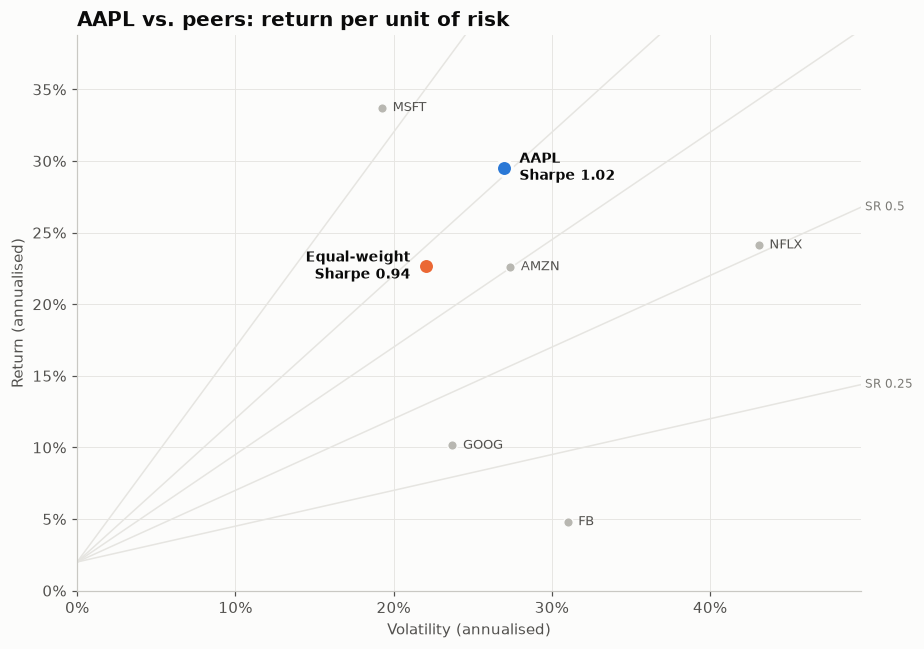

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 6))
others = stats.drop([highlight, benchmark])
xmax = stats["ann_vol"].max() * 1.15
for sharpe in [0.25, 0.5, 0.75, 1.0, 1.5]:
    ax.plot([0, xmax], [rf, rf + sharpe * xmax], color="#e6e5e1", linewidth=1, zorder=1)
    y_end = rf + sharpe * xmax
    if y_end < stats["ann_return"].max() * 1.15:
        ax.text(xmax, y_end, f" SR {sharpe}", fontsize=8, color="#7a7974", va="center")
ax.scatter(others["ann_vol"], others["ann_return"], s=40, color=GRAY, edgecolor="#fcfcfb", linewidth=1, zorder=2)
if len(others) <= 8:  # few peers: name them
    for name, (x, y) in others.iterrows():
        ax.annotate(name, (x, y), xytext=(7, 0), textcoords="offset points", va="center", fontsize=8.5,
                    color="#52514e")
for name, color in [(benchmark, PALETTE[1]), (highlight, PALETTE[0])]:
    x, y = stats.loc[name]
    ax.scatter(x, y, s=110, color=color, edgecolor="#fcfcfb", linewidth=2, zorder=3)
    left = name == benchmark
    ax.annotate(f"{name}\nSharpe {(y - rf) / x:.2f}", (x, y), xytext=(-10 if left else 10, 0),
                textcoords="offset points", ha="right" if left else "left", va="center", fontsize=9,
                weight="bold", color="#0b0b0b")
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, xmax)
ax.set_ylim(min(0, stats["ann_return"].min() * 1.1), stats["ann_return"].max() * 1.15)
ax.set_xlabel("Volatility (annualised)")
ax.set_ylabel("Return (annualised)")
ax.set_title(f"{highlight} vs. peers: return per unit of risk")
fig.tight_layout()
plt.show()

---
Standalone script: [`risk_return_scatter.py`](risk_return_scatter.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)